# Initial Setup

In [81]:
# Install the YOLO object detector, which is not included in Colab by default
!pip install -q ultralytics

# Files, numbers, plots and tables
import os
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import rgb_to_hsv

# Images and object detection
from PIL import Image, ImageOps
from ultralytics import YOLO

# Neural networks (TensorFlow/Keras) and the pretrained MobileNetV2
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Classic machine learning tools and evaluation metrics (scikit-learn)
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

# Access to Google Drive
from google.colab import drive

# Where the photos are, and where the new versions will be saved
RAW_DIR  = '/content/drive/MyDrive/data/raw'
CROP_DIR = '/content/drive/MyDrive/data_cropped'
AUG_DIR  = '/content/drive/MyDrive/data_augmented'
IMG_SIZE = 224                # every image is resized to 224 x 224 pixels
HOT_CHOC = 'hot_chocolate'   # name of the hot chocolate folder

# Remove leftover folders from earlier failed runs
shutil.rmtree(f'{CROP_DIR}/.DS_Store', ignore_errors=True)
shutil.rmtree(f'{CROP_DIR}/raw', ignore_errors=True)

# Helper function used throughout the notebook to list the photos in a folder
def list_images(folder):
    """Return only the image files in a folder (skips hidden files like .DS_Store)."""
    return sorted(f for f in os.listdir(folder) if f.lower().endswith(('.jpg', '.jpeg', '.png')))

# Only keep real folders: each folder name is a drink label (e.g. 'cappuccino', 'hot_chocolate', 'iced_latte', 'matcha')
CLASSES = sorted(d for d in os.listdir(RAW_DIR) if os.path.isdir(f'{RAW_DIR}/{d}'))
print(CLASSES)

['cappuccino', 'hot_chocolate', 'iced_latte', 'matcha']


# Preprocessing and Cropping

In [82]:
# Load a small pretrained YOLOv8 object detector
detector = YOLO('yolov8n.pt')
# YOLO knows 80 kinds of objects; we only keep the ones a drink is served in
DRINK_TYPES = [k for k, name in detector.names.items() if name in ('cup', 'wine glass', 'bottle')]

# Takes one photo and returns a zoomed-in, square 224 x 224 image of the drink
def zoom_on_drink(img):
    # Ask YOLO to draw boxes around any cups, glasses or bottles in the photo
    boxes = detector(img, classes=DRINK_TYPES, verbose=False)[0].boxes.xyxy.tolist()

    # No drink found: fall back to the center of the photo
    if not boxes:
        return ImageOps.fit(img, (IMG_SIZE, IMG_SIZE))

    # Use the biggest box (your drink is usually the main subject)
    x1, y1, x2, y2 = max(boxes, key=lambda b: (b[2] - b[0]) * (b[3] - b[1]))

    # Square crop slightly larger than the drink, kept inside the photo.
    # A square avoids stretching, so the glass shape stays realistic.
    side = min(max(x2 - x1, y2 - y1) * 1.15, img.width, img.height)   # 15% bigger than the drink
    left = min(max((x1 + x2) / 2 - side / 2, 0), img.width - side)    # center the square on the drink...
    top  = min(max((y1 + y2) / 2 - side / 2, 0), img.height - side)   # ...without going outside the photo
    return img.crop((left, top, left + side, top + side)).resize((IMG_SIZE, IMG_SIZE))

# Go through every photo of every drink, zoom in on the drink, and save the result in a new folder with the same structure
for drink in CLASSES:
    os.makedirs(f'{CROP_DIR}/{drink}', exist_ok=True)
    for file in list_images(f'{RAW_DIR}/{drink}'):
        img = ImageOps.exif_transpose(Image.open(f'{RAW_DIR}/{drink}/{file}')).convert('RGB')  # fix phone rotation
        zoom_on_drink(img).save(f'{CROP_DIR}/{drink}/{file}')

print('Done cropping!')

Done cropping!


# Data Augmentation

In [83]:
# A small pipeline of random edits; each image passes through all of them
augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal'),                   # mirror left/right
    tf.keras.layers.RandomRotation(0.05),                       # tilt by up to about 18 degrees
    tf.keras.layers.RandomZoom(0.15),                           # zoom in or out by up to 15%
    tf.keras.layers.RandomTranslation(0.1, 0.1),                # shift by up to 10% in any direction
    tf.keras.layers.RandomBrightness(0.1, value_range=(0, 1)),  # make slightly brighter or darker
])

# Load the cropped hot chocolate photos (pixel values scaled to 0-1)
files = list_images(f'{CROP_DIR}/{HOT_CHOC}')
originals = np.array([np.array(Image.open(f'{CROP_DIR}/{HOT_CHOC}/{f}')) / 255 for f in files])

# Make enough new photos to match the average of the other drinks
others = [len(list_images(f'{CROP_DIR}/{d}')) for d in CLASSES if d != HOT_CHOC]
n_new = int(np.mean(others)) - len(files)

# Cycle through the originals and make one edited copy per pick
# (e.g. photo 1, 2, 3, ..., then photo 1, 2, 3 again), so every real photo is used evenly
tf.random.set_seed(42)   # fixed seed, so the same edits are made every time the notebook runs
picks = np.arange(n_new) % len(files)
new_images = augment(originals[picks], training=True).numpy().clip(0, 1)

# Save them; the filename records which real photo each copy came from
# (e.g. 'IMG_1234_aug3.jpg'), so copies of test photos can be left out later
os.makedirs(f'{AUG_DIR}/{HOT_CHOC}', exist_ok=True)
for i, img in enumerate(new_images):
    source = os.path.splitext(files[picks[i]])[0]
    Image.fromarray((img * 255).astype('uint8')).save(f'{AUG_DIR}/{HOT_CHOC}/{source}_aug{i}.jpg')

print(f'{len(files)} real + {n_new} new = {len(files) + n_new} hot chocolate photos')

11 real + 11 new = 22 hot chocolate photos


# Checking the Cropped Images

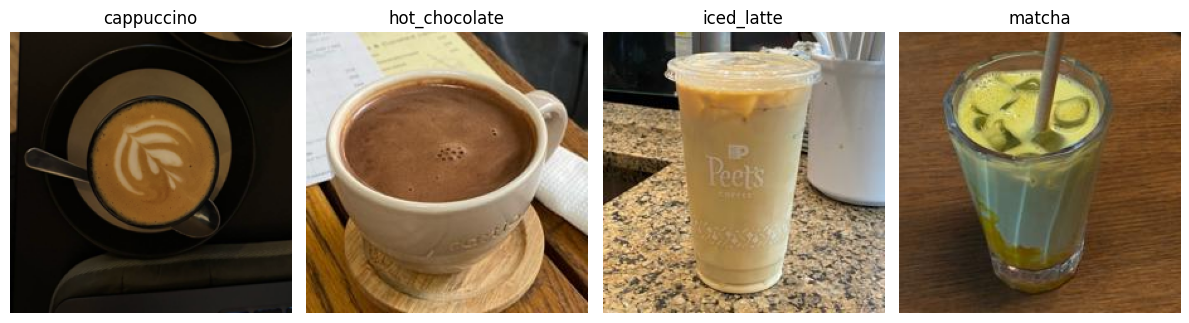

In [84]:
# Create one row of small plots, one for each drink
fig, axes = plt.subplots(1, len(CLASSES), figsize=(12, 3.5))

# For every drink, show the first cropped photo with the drink's name as the title
for i, drink in enumerate(CLASSES):
    first = list_images(f'{CROP_DIR}/{drink}')[0]
    axes[i].imshow(Image.open(f'{CROP_DIR}/{drink}/{first}'))
    axes[i].set_title(drink)
    axes[i].axis('off')   # hide the axis ticks, since we are only looking at pictures

plt.tight_layout()   # space the plots neatly
plt.show()

# Comparing Original and Augmented Hot Chocolate Images

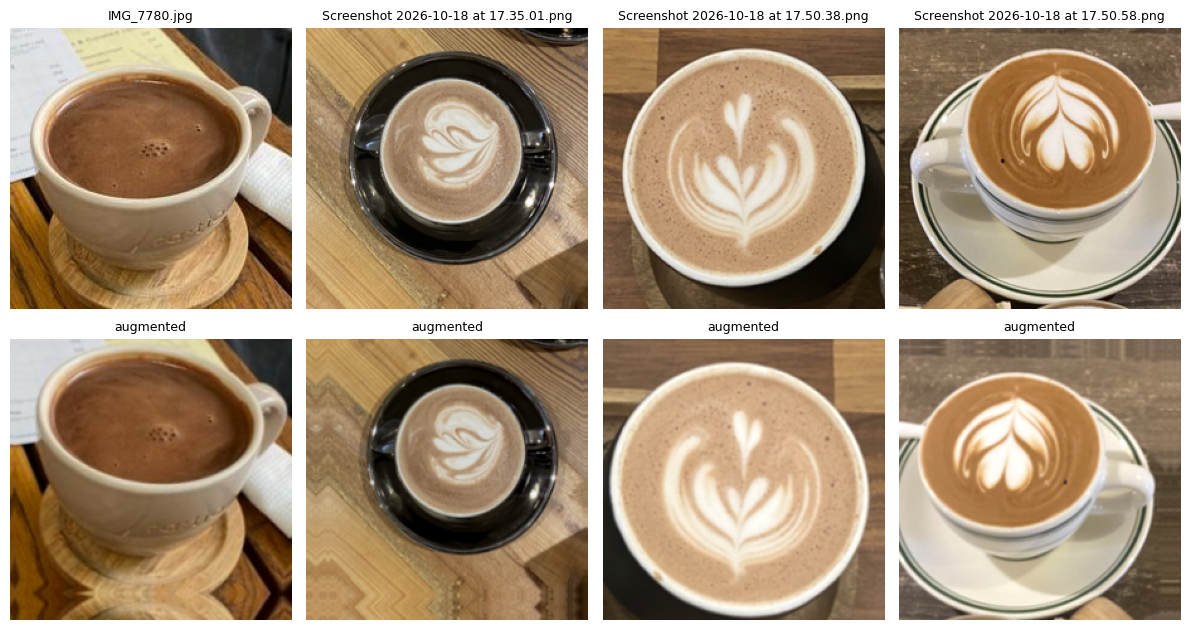

In [85]:
# Create a grid with 2 rows and 4 columns: real photos on top, edited copies below
fig, axes = plt.subplots(2, 4, figsize=(12, 6.5))

# Show four pairs; each column is one real photo and the copy made from it
for i in range(4):
    axes[0, i].imshow(originals[picks[i]])   # picks[i] = which original copy i was made from
    axes[0, i].set_title(files[picks[i]], fontsize=9)   # filename of the real photo
    axes[1, i].imshow(new_images[i])
    axes[1, i].set_title('augmented', fontsize=9)

# Hide the axis ticks, since we are only looking at pictures
for ax in axes.flat:
    ax.axis('off')
plt.tight_layout()   # space the plots neatly
plt.show()

# Splitting the Data into Training and Test Sets

In [86]:
# Load all real cropped photos, their labels, and their filenames
# X = the images, y = the drink of each image as a number (0-3), names = filenames
X, y, names = [], [], []
for label, drink in enumerate(CLASSES):
    for f in list_images(f'{CROP_DIR}/{drink}'):
        X.append(np.array(Image.open(f'{CROP_DIR}/{drink}/{f}')) / 255)   # pixel values scaled to 0-1
        y.append(label)
        names.append(os.path.splitext(f)[0])
X, y, names = np.array(X), np.array(y), np.array(names)

# Split the real photos 80/20; stratify keeps each drink's share equal in both sets
# random_state=42 makes the split the same every time the notebook runs
X_train, X_test, y_train, y_test, names_train, names_test = train_test_split(
    X, y, names, test_size=0.2, stratify=y, random_state=42)

# Add augmented hot chocolates whose source photo is in the training set
# (copies of test photos are left out, so the model is never tested on a photo it has seen)
hot_label = CLASSES.index(HOT_CHOC)
train_sources = set(names_train[y_train == hot_label])   # names of the real hot chocolates in training
aug_X = []
for f in list_images(f'{AUG_DIR}/{HOT_CHOC}'):
    source = f.split('_aug')[0]           # 'IMG_1234_aug3.jpg' -> 'IMG_1234'
    if source in train_sources:
        aug_X.append(np.array(Image.open(f'{AUG_DIR}/{HOT_CHOC}/{f}')) / 255)

# Append the selected augmented images (and their hot chocolate label) to the training set
X_train = np.concatenate([X_train, np.array(aug_X)])
y_train = np.concatenate([y_train, np.full(len(aug_X), hot_label)])

# Show how many photos of each drink ended up in each set
print('Train:', dict(zip(CLASSES, np.bincount(y_train))))
print('Test: ', dict(zip(CLASSES, np.bincount(y_test))))

Train: {'cappuccino': np.int64(19), 'hot_chocolate': np.int64(18), 'iced_latte': np.int64(15), 'matcha': np.int64(18)}
Test:  {'cappuccino': np.int64(5), 'hot_chocolate': np.int64(2), 'iced_latte': np.int64(4), 'matcha': np.int64(5)}


# Measuring How Different the Drinks Are in Color

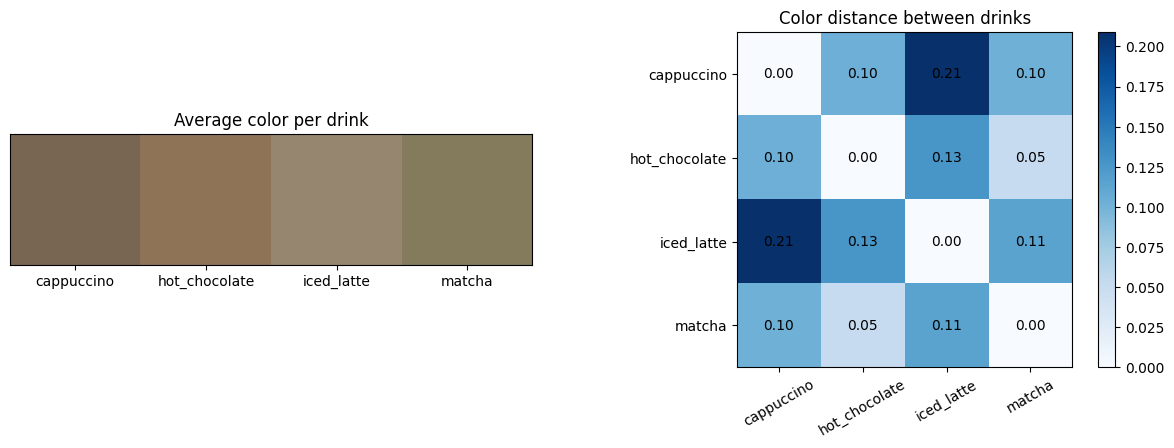

In [87]:
# Typical color of each drink: average red, green and blue over all its real photos
mean_colors = np.array([X[y == k].mean(axis=(0, 1, 2)) for k in range(len(CLASSES))])

# Distance between every pair of drinks (bigger = more different in color)
# This is the straight-line distance between two colors, treating red, green and blue as coordinates
dist = np.linalg.norm(mean_colors[:, None] - mean_colors[None, :], axis=2)

# Create two plots side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Left: the typical color of each drink as a swatch
axes[0].imshow(mean_colors[None, :, :])
axes[0].set_xticks(range(len(CLASSES)), CLASSES)
axes[0].set_yticks([])
axes[0].set_title('Average color per drink')

# Right: color distance between each pair
# (a grid where each cell shows how different two drinks are; darker blue = more different)
im = axes[1].imshow(dist, cmap='Blues')
axes[1].set_xticks(range(len(CLASSES)), CLASSES, rotation=30)
axes[1].set_yticks(range(len(CLASSES)), CLASSES)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        axes[1].text(j, i, f'{dist[i, j]:.2f}', ha='center', va='center')   # write the number in each cell
axes[1].set_title('Color distance between drinks')
plt.colorbar(im, ax=axes[1])   # color scale legend

plt.tight_layout()
plt.show()

# Training Models A and B

In [94]:
results = {}   # stores every model's predictions and scores for the comparison later

# Helper function: lets a trained model guess the drink in every test photo,
# compares the guesses with the true labels, and saves and prints the scores
def evaluate(name, model, X_te):
    preds = model.predict(X_te)
    results[name] = {'preds': preds,
                     'accuracy': accuracy_score(y_test, preds),                  # share of photos correct
                     'macro F1': f1_score(y_test, preds, average='macro')}      # average score per drink
    print(f"{name}: accuracy = {results[name]['accuracy']:.2f}, macro F1 = {results[name]['macro F1']:.2f}")

# Model A: raw pixels
# Shrink each photo to 32 x 32 pixels and turn it into one long list of 3,072 numbers
def small_pixels(imgs):
    return tf.image.resize(imgs, (32, 32)).numpy().reshape(len(imgs), -1)

# StandardScaler puts all numbers on the same scale; logistic regression then learns
# which numbers point to which drink
model_a = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
model_a.fit(small_pixels(X_train), y_train)          # learn from the training photos
evaluate('A: raw pixels', model_a, small_pixels(X_test))   # test on the unseen photos

# Model B: color histograms
# Describe each photo by how much of each color it contains, ignoring where the colors are
def color_histogram(img, bins=16):
    hsv = rgb_to_hsv(img)   # hue, saturation, brightness, each between 0 and 1
    # split hue, saturation and brightness into 16 ranges each and count the pixels in every range
    counts = [np.histogram(hsv[..., c], bins=bins, range=(0, 1))[0] for c in range(3)]
    return np.concatenate(counts) / (img.shape[0] * img.shape[1])   # fraction of pixels per range

# Turn every training and test photo into its 48 color numbers
hist_train = np.array([color_histogram(img) for img in X_train])
hist_test  = np.array([color_histogram(img) for img in X_test])

# Same classifier as model A, but trained on the color summaries instead of raw pixels
model_b = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
model_b.fit(hist_train, y_train)
evaluate('B: color histograms', model_b, hist_test)

A: raw pixels: accuracy = 0.38, macro F1 = 0.30
B: color histograms: accuracy = 0.44, macro F1 = 0.38


# Training Model C with MobileNetV2

In [95]:
# Pretrained network without its final layer; outputs 1,280 numbers per image
base = MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights='imagenet', pooling='avg')
base.trainable = False   # keep its learned knowledge frozen

# Turn every photo into its 1,280 features (MobileNetV2 expects pixels in 0-255)
feat_train = base.predict(preprocess_input(X_train * 255), verbose=0)
feat_test  = base.predict(preprocess_input(X_test * 255), verbose=0)

# Small classifier on top: dropout (to reduce overfitting) + one softmax layer for our 4 drinks
# Dropout randomly ignores 30% of the features during each training step, so the model
# can't rely too much on any single one; softmax gives a probability for each drink
tf.random.set_seed(42)
model_c = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(1280,)),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(len(CLASSES), activation='softmax'),
])
# Adam adjusts the weights step by step to reduce the cross-entropy loss (how wrong the guesses are)
model_c.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Shuffle first, so the 20% validation slice isn't just the augmented images (they sit at the end)
# Train for 50 rounds (epochs); 20% of the training data is held back to track progress,
# and 'history' records the scores after each round for the learning curves
order = np.random.default_rng(42).permutation(len(feat_train))
history = model_c.fit(feat_train[order], y_train[order], validation_split=0.2, epochs=50, verbose=0)

# Score on the test set, stored the same way as models A and B
# (argmax picks the drink with the highest probability for each photo)
preds_c = model_c.predict(feat_test, verbose=0).argmax(axis=1)
results['C: MobileNetV2'] = {'preds': preds_c,
                             'accuracy': accuracy_score(y_test, preds_c),
                             'macro F1': f1_score(y_test, preds_c, average='macro')}
print(f"C: MobileNetV2: accuracy = {results['C: MobileNetV2']['accuracy']:.2f}, "
      f"macro F1 = {results['C: MobileNetV2']['macro F1']:.2f}")

C: MobileNetV2: accuracy = 0.56, macro F1 = 0.56


# Comparing the Three Models

,Accuracy,Macro F1
A: raw pixels,0.38,0.30
B: color histograms,0.44,0.38
C: MobileNetV2,0.56,0.56


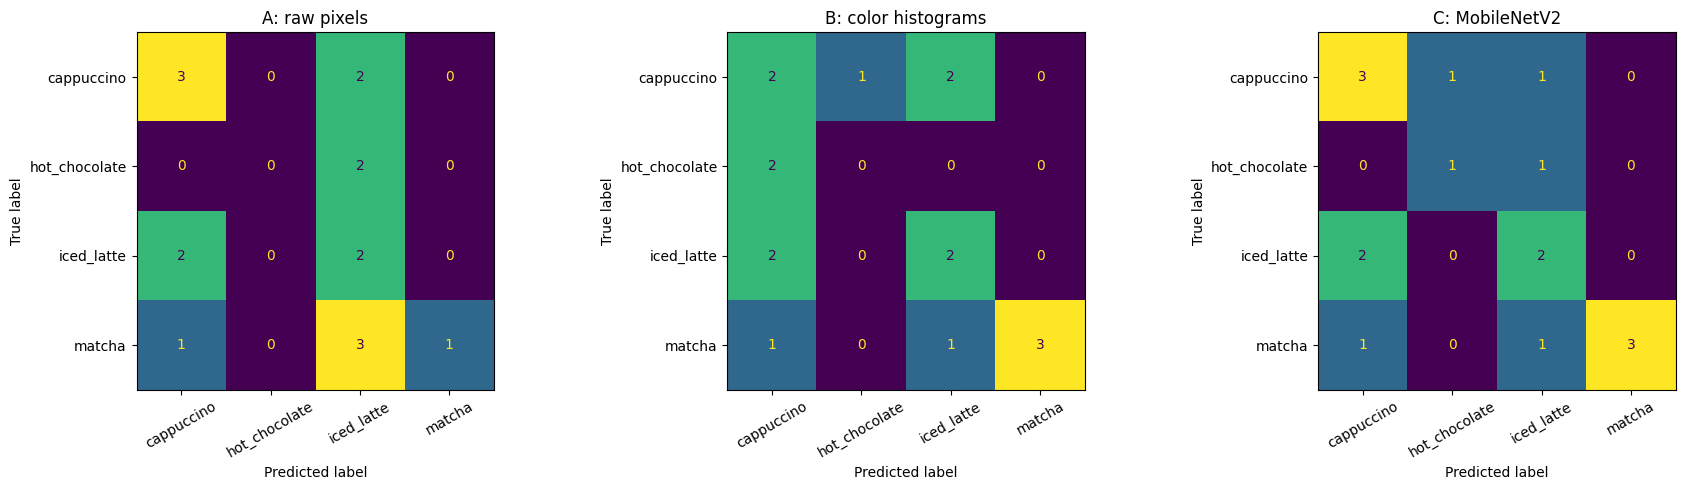

In [96]:
# Comparison table
# One row per model, with its accuracy and macro F1 score rounded to 2 decimals
table = pd.DataFrame({name: {'Accuracy': r['accuracy'], 'Macro F1': r['macro F1']}
                      for name, r in results.items()}).T.round(2)
display(table)

# Confusion matrices side by side
# Each row is the true drink and each column is the model's guess, so the numbers
# on the diagonal are correct predictions and everything else is a mix-up
fig, axes = plt.subplots(1, len(results), figsize=(6 * len(results), 5))
for ax, (name, r) in zip(axes, results.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, r['preds'], display_labels=CLASSES,
                                            ax=ax, colorbar=False, xticks_rotation=30)
    ax.set_title(name)
plt.tight_layout()
plt.show()

# Per-Drink Breakdown of the Results

,A: raw pixels,B: color histograms,C: MobileNetV2
cappuccino,3/5 (60%),2/5 (40%),3/5 (60%)
hot_chocolate,0/2 (0%),0/2 (0%),1/2 (50%)
iced_latte,2/4 (50%),2/4 (50%),2/4 (50%)
matcha,1/5 (20%),3/5 (60%),3/5 (60%)
Overall,6/16 (38%),7/16 (44%),9/16 (56%)
Macro F1,0.30,0.38,0.56


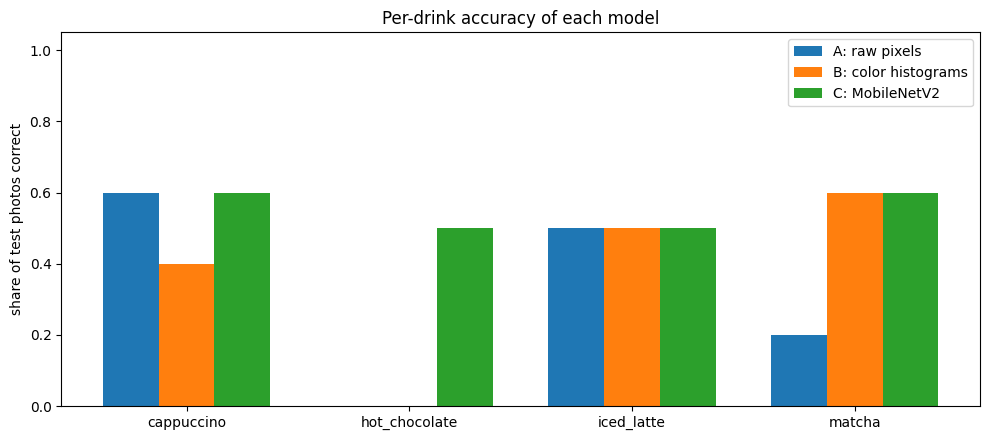

In [97]:
# Build a table: for every model, count how many test photos of each drink it got right
breakdown = {}
for name, r in results.items():
    cm = confusion_matrix(y_test, r['preds'], labels=range(len(CLASSES)))
    correct = cm.diagonal()    # right answers per drink (the diagonal of the confusion matrix)
    total = cm.sum(axis=1)     # test photos per drink
    # Write each result as "correct/total (percentage)", e.g. "4/5 (80%)"
    column = {drink: f'{c}/{t} ({c / t:.0%})' for drink, c, t in zip(CLASSES, correct, total)}
    column['Overall'] = f'{correct.sum()}/{total.sum()} ({r["accuracy"]:.0%})'
    column['Macro F1'] = f'{r["macro F1"]:.2f}'
    breakdown[name] = column

display(pd.DataFrame(breakdown))   # one column per model, one row per drink

# Bar chart: per-drink accuracy for each model
# Each drink gets a group of three bars, one per model, placed next to each other
fig, ax = plt.subplots(figsize=(10, 4.5))
width = 0.25
for i, (name, r) in enumerate(results.items()):
    cm = confusion_matrix(y_test, r['preds'], labels=range(len(CLASSES)))
    per_drink = cm.diagonal() / cm.sum(axis=1)   # share of each drink's test photos classified correctly
    ax.bar(np.arange(len(CLASSES)) + i * width, per_drink, width, label=name)

# Labels, axis range and legend
ax.set_xticks(np.arange(len(CLASSES)) + width, CLASSES)
ax.set_ylabel('share of test photos correct')
ax.set_ylim(0, 1.05)
ax.set_title('Per-drink accuracy of each model')
ax.legend()
plt.tight_layout()
plt.show()